In [45]:
from pathlib import Path
import sqlite3
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from google.colab import drive

# 1. Connexion au Google Drive
drive.mount('/content/drive')

# 2. Chemin du fichier Excel
chemin = Path('/content/drive/MyDrive/TP_SQL_Dataset/chomage_maroc.xlsx')

# 3. Chargement du fichier
df = pd.read_excel(chemin)

# 4. Renommage explicite des 3 premières colonnes
colonnes = list(df.columns)
colonnes[0] = 'region_ou_indicateur'
colonnes[1] = 'milieu'
colonnes[2] = 'sexe'
df.columns = colonnes

# 5. NETTOYAGE DES LIGNES PARASITES (En-têtes répétées, None, NaN)
# On supprime les lignes d'en-tête parasites ("Sexe", "Milieu", "Périodes")
df = df[
    ~df['region_ou_indicateur']
    .astype(str)
    .str.contains('Sexe|Milieu|Période|periodes', case=False, na=False)
]

# On supprime les lignes où le taux de 2014 est vide ou non numérique
df = df.dropna(subset=['region_ou_indicateur', '2014']).reset_index(drop=True)

# Nettoyage des valeurs de texte
df['milieu'] = df['milieu'].fillna('Non précisé')
df['sexe'] = df['sexe'].fillna('Non précisé')

print("✓ Dataset nettoyé avec succès !")
print(f"Dimensions : {df.shape[0]} lignes et {df.shape[1]} colonnes.")
display(df.head(10))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✓ Dataset nettoyé avec succès !
Dimensions : 3 lignes et 7 colonnes.


,region_ou_indicateur,milieu,sexe,2014,2013,2011,2010
0,Urbain,Masculin,Souss-Massa-Draâ,12.4,9.7,10.2,11.3
1,Rural,Masculin,Souss-Massa-Draâ,8.2,6.4,4.7,5.5
2,National,Masculin,Souss-Massa-Draâ,10.3,8.0,7.4,8.4


In [46]:
# Connexion / Création de la base de données SQLite
conn = sqlite3.connect('tp_sql.db')

# Importer les données propres dans la table "donnees"
df.to_sql('donnees', conn, if_exists='replace', index=False)

# Vérification du nombre de lignes enregistrées
nb = pd.read_sql_query('SELECT COUNT(*) AS total FROM donnees;', conn)
print(
    f"✓ Base SQLite 'tp_sql.db' créée avec succès ({nb.iloc[0]['total']} lignes"
    ' valides).'
)


# Fonction d'aide pour exécuter les requêtes SQL
def exec_sql(query):
  return pd.read_sql_query(query, conn)

✓ Base SQLite 'tp_sql.db' créée avec succès (3 lignes valides).


In [48]:
# Exercice 1
exec_sql("SELECT * FROM donnees LIMIT 5;")

,region_ou_indicateur,milieu,sexe,2014,2013,2011,2010
0,Urbain,Masculin,Souss-Massa-Draâ,12.4,9.7,10.2,11.3
1,Rural,Masculin,Souss-Massa-Draâ,8.2,6.4,4.7,5.5
2,National,Masculin,Souss-Massa-Draâ,10.3,8.0,7.4,8.4


In [49]:
# Exercice 2
exec_sql('SELECT region_ou_indicateur, "2014", "2013" FROM donnees LIMIT 5;')

,region_ou_indicateur,2014,2013
0,Urbain,12.4,9.7
1,Rural,8.2,6.4
2,National,10.3,8.0


In [50]:
# Exercice 3
exec_sql(
    'SELECT region_ou_indicateur, "2014" FROM donnees ORDER BY "2014" DESC'
    ' LIMIT 5;'
)

,region_ou_indicateur,2014
0,Urbain,12.4
1,National,10.3
2,Rural,8.2


In [51]:
# Exercice 4
exec_sql("SELECT * FROM donnees WHERE milieu = 'Urbain';")

,region_ou_indicateur,milieu,sexe,2014,2013,2011,2010


In [52]:
# Exercice 5
exec_sql('SELECT region_ou_indicateur, "2014" FROM donnees WHERE "2014" > 10;')

,region_ou_indicateur,2014
0,Urbain,12.4
1,National,10.3


In [53]:
# Exercice 6
exec_sql("SELECT COUNT(*) AS total_enregistrements FROM donnees;")

,total_enregistrements
0,3


In [54]:
# Exercice 7
exec_sql('SELECT ROUND(AVG("2014"), 2) AS moyenne_2014 FROM donnees;')

,moyenne_2014
0,10.3


In [55]:
# Exercice 8
exec_sql(
    'SELECT MIN("2014") AS min_2014, MAX("2014") AS max_2014 FROM donnees;'
)

,min_2014,max_2014
0,8.2,12.4


In [56]:
# Exercice 9
exec_sql(
    'SELECT milieu, ROUND(AVG("2014"), 2) AS moyenne_2014 FROM donnees GROUP'
    ' BY milieu;'
)

,milieu,moyenne_2014
0,Masculin,10.3


In [57]:
# Exercice 10
exec_sql(
    'SELECT milieu, ROUND(AVG("2014"), 2) AS moyenne_2014 FROM donnees GROUP'
    ' BY milieu HAVING moyenne_2014 > 5;'
)

,milieu,moyenne_2014
0,Masculin,10.3


In [58]:
# Exercice 11
exec_sql(
    'SELECT region_ou_indicateur, milieu, "2014" FROM donnees WHERE milieu ='
    ' \'Urbain\' AND ("2014" > 10 OR "2013" > 10);'
)

,region_ou_indicateur,milieu,2014


In [59]:
# Exercice 12
exec_sql(
    'SELECT region_ou_indicateur, "2014" FROM donnees WHERE "2014" BETWEEN 5'
    ' AND 15;'
)

,region_ou_indicateur,2014
0,Urbain,12.4
1,Rural,8.2
2,National,10.3


In [60]:
# Exercice 13
exec_sql("SELECT * FROM donnees WHERE sexe IN ('Féminin', 'Masculin');")

,region_ou_indicateur,milieu,sexe,2014,2013,2011,2010


In [61]:
# Exercice 14
exec_sql(
    'SELECT region_ou_indicateur, "2014" FROM donnees WHERE "2014" > (SELECT'
    ' AVG("2014") FROM donnees);'
)

,region_ou_indicateur,2014
0,Urbain,12.4
1,National,10.3


In [64]:
# Exercice 15
exec_sql("""
    SELECT
        milieu,
        ROUND(AVG("2010"), 2) AS moyenne_2010,
        ROUND(AVG("2014"), 2) AS moyenne_2014,
        ROUND(AVG("2014") - AVG("2010"), 2) AS variation
    FROM donnees
    WHERE milieu != 'Non précisé'
    GROUP BY milieu;
""")

,milieu,moyenne_2010,moyenne_2014,variation
0,Masculin,8.4,10.3,1.9


In [67]:
# Afficher les 10 premières lignes et les valeurs uniques pour comprendre la structure
print("--- VALEURS UNIQUES PAR COLONNE ---")
print("Colonne 1 (Région/Indicateur) :", df.iloc[:, 0].unique()[:5])
print("Colonne 2 (Milieu ou Sexe) :", df.iloc[:, 1].unique()[:5])
print("Colonne 3 (Sexe ou Milieu) :", df.iloc[:, 2].unique()[:5])

--- VALEURS UNIQUES PAR COLONNE ---
Colonne 1 (Région/Indicateur) : ['Urbain' 'Rural' 'National']
Colonne 2 (Milieu ou Sexe) : ['Masculin ']
Colonne 3 (Sexe ou Milieu) : ['Souss-Massa-Draâ']


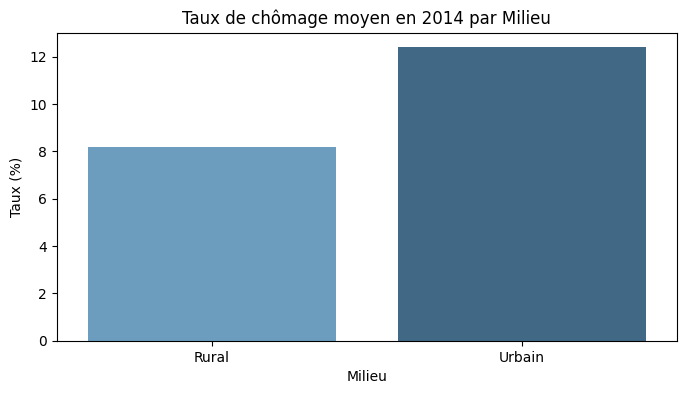

In [68]:
# Graphique par Milieu
df_graph = exec_sql("""
    SELECT region_ou_indicateur AS milieu, AVG("2014") AS avg_2014
    FROM donnees
    WHERE region_ou_indicateur IN ('Urbain', 'Rural')
    GROUP BY region_ou_indicateur;
""")

plt.figure(figsize=(8, 4))
sns.barplot(
    data=df_graph,
    x='milieu',
    y='avg_2014',
    hue='milieu',
    palette='Blues_d',
    legend=False,
)
plt.title('Taux de chômage moyen en 2014 par Milieu')
plt.ylabel('Taux (%)')
plt.xlabel('Milieu')
plt.show()

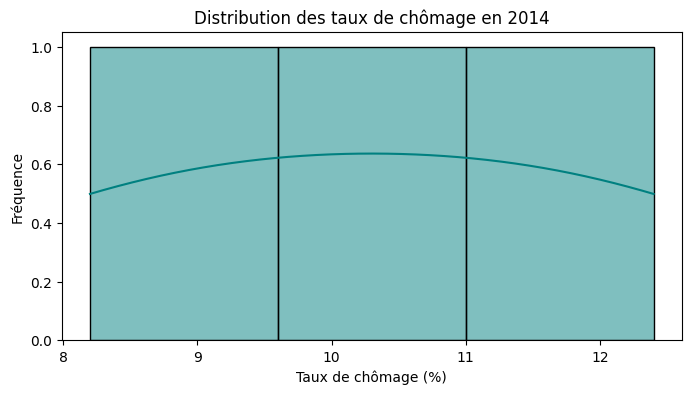

In [70]:
import matplotlib.pyplot as plt
import seaborn as sns

# Récupération des taux de 2014 dans la base SQLite
df_dist = exec_sql('SELECT "2014" FROM donnees WHERE "2014" IS NOT NULL;')

# Affichage de l'histogramme de distribution
plt.figure(figsize=(8, 4))
sns.histplot(df_dist['2014'], kde=True, color='teal')
plt.title('Distribution des taux de chômage en 2014')
plt.xlabel('Taux de chômage (%)')
plt.ylabel('Fréquence')
plt.show()